In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import random
from numpy.polynomial import Polynomial
from numpy.polynomial import Chebyshev

from scipy.optimize import brentq

random.seed(42)

In [2]:
def rossler_system(t, state, a, b, c):
  x, y, z = state

  x_d_dot = -y - z
  y_d_dot = x + a * y
  z_d_dot = b + z * (x - c)

  return [x_d_dot, y_d_dot, z_d_dot]

### part a

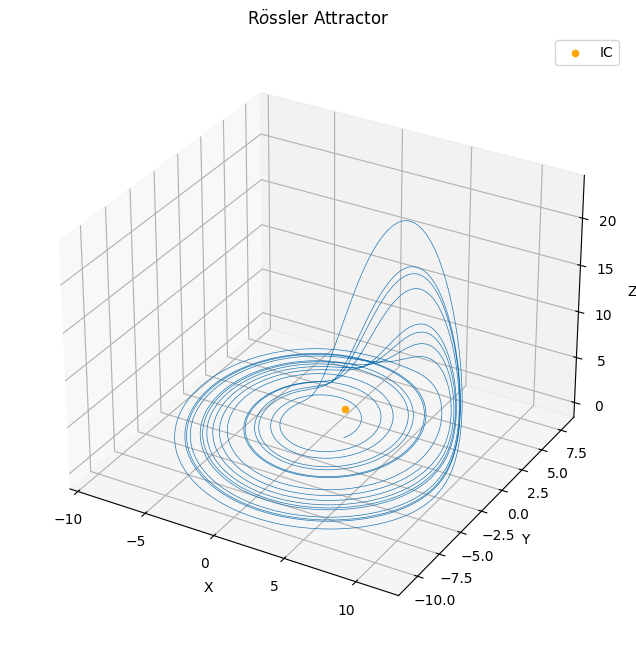

In [39]:
t_max = 100
t = np.linspace(0, t_max, 10000)  # delta t = 10E-5

ic = [1, 1, 1]   # initial condition

# given parameters
a = 0.2
b = 0.2
c = 5.7

# solve system
solution = solve_ivp(rossler_system, (0,t_max), ic,
                     args=(a, b, c), t_eval=t)

# remove first 500 solutions from solution
solution.y = solution.y[:, 500:]

fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# coordinates to plot
x, y, z = solution.y

# plot result
ax.plot3D(x, y, z, lw=0.5)
ax.scatter(ic[0], ic[1], ic[2],
           label = "IC",
           color = 'orange')

ax.set_xlabel("X")
ax.set_ylabel("Y")
ax.set_zlabel("Z")
ax.set_title(r"R$\ddot{o}$ssler Attractor")
ax.legend()
ax.set_box_aspect(None, zoom=0.95) # so we can see the z-axis label
plt.show()

### part b

In [40]:
# collect at least 200 points (x, z) where x < 0 and y = 0
t_max = 5000

# find where x < 0
# within that set, find where y changes sign
# interpolate (x,z)

# Poincare map
# we seek where this is zero
def p_map(t, state, *args):
  return state[1] # return y(t)

# record where trajectory crosses y=0,
#   moving from y(t) > 0 to y(t) < 0
p_map.direction = -1

# solve system
#   The events parameter tells the computer
#   to only store where the event occurs.
#   Event occurrence is interpolated under the hood.
#   So, this will only return where y(t) = 0
solution = solve_ivp(rossler_system, (0,t_max), ic,
                     args=(a, b, c),
                     events = p_map,
                     rtol=1e-10,
                     atol=1e-12)

In [41]:
crossings = solution.y_events[0]
crossing_times = solution.t_events[0]

# remove transient solutions
crossings2 = crossings[crossing_times > 100]
sigma_points = crossings2[crossings2[:, 0] < 0][:, [0, 2]]

print(f'There are {len(sigma_points)} intersections with sigma.')

There are 837 intersections with sigma.


### part c

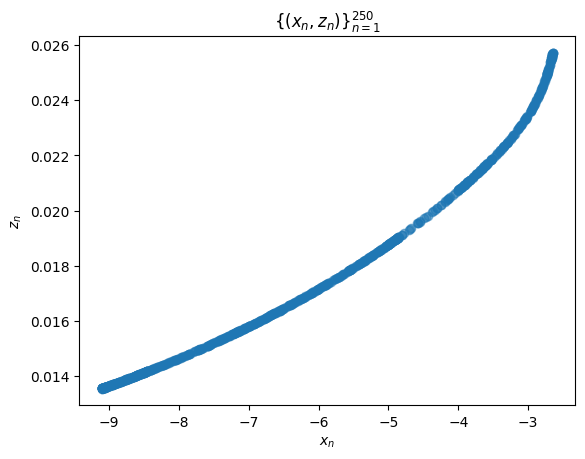

In [42]:
# plot (x_n, z_n)
plt.scatter(sigma_points[:, 0], sigma_points[:, 1],
            alpha = 0.5)
plt.xlabel(r"$x_n$")
plt.ylabel(r"$z_n$")
plt.title(r"$\{(x_n, z_n)\}_{n=1}^{250}$")
plt.show()

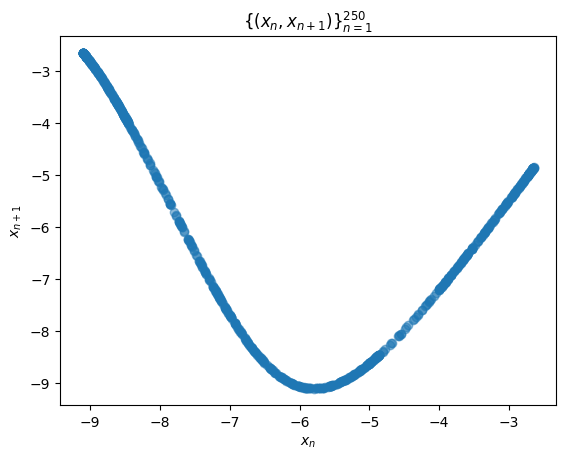

In [43]:
# plot (x_n, x_{n+1})
plt.scatter(sigma_points[:-1, 0], sigma_points[1:, 0],
            alpha = 0.5)
plt.xlabel(r"$x_n$")
plt.ylabel("$x_{n+1}$")
plt.title(r"$\{(x_n, x_{n+1})\}_{n=1}^{250}$")
plt.show()

### part d

In [44]:
# fit a degree 10 polynomial for the {x_n, z_n} points
poly_Q = Chebyshev.fit(sigma_points[:, 0], sigma_points[:, 1], deg=10)
print(f'Polynomial Q:\n{poly_Q}')
print(f'\nQ Coefficients:\n{poly_Q.convert().coef}')

# fit a degree 10 polynomial for the {x_n, x_(n+1)} points
poly_P = Chebyshev.fit(sigma_points[:-1, 0], sigma_points[1:,0], deg=10)
print(f'\n\nPolynomial P:\n{poly_P}')
print(f'\nP Coefficients:\n{poly_P.convert().coef}')

Polynomial Q:
0.01824283 + 0.00550238·T₁((1.81967014 + 0.30966129x)) +
0.0010349·T₂((1.81967014 + 0.30966129x)) +
0.00034779·T₃((1.81967014 + 0.30966129x)) +
0.00020036·T₄((1.81967014 + 0.30966129x)) +
0.00013433·T₅((1.81967014 + 0.30966129x)) +
(9.20373333e-05)·T₆((1.81967014 + 0.30966129x)) +
(6.21149026e-05)·T₇((1.81967014 + 0.30966129x)) +
(4.09931649e-05)·T₈((1.81967014 + 0.30966129x)) +
(2.52815232e-05)·T₉((1.81967014 + 0.30966129x)) +
(1.43096457e-05)·T₁₀((1.81967014 + 0.30966129x))

Q Coefficients:
[4.58010009e+00 5.98056886e+00 2.15623317e+00 4.84854094e-01
 7.24812056e-02 7.42373049e-03 5.24445777e-04 2.51619644e-05
 7.83615843e-07 1.42962179e-08 1.16010688e-10]


Polynomial P:
-6.01513562 - 1.16874392·T₁((1.81967014 + 0.30966129x)) +
2.61490601·T₂((1.81967014 + 0.30966129x)) -
0.00595193·T₃((1.81967014 + 0.30966129x)) -
0.39505574·T₄((1.81967014 + 0.30966129x)) +
0.08293479·T₅((1.81967014 + 0.30966129x)) +
0.05614904·T₆((1.81967014 + 0.30966129x)) -
0.0178412·T₇((1.81967014 

In [45]:
# fit a degree 10 polynomial for the {x_n, z_n} points
poly_Q = Polynomial.fit(sigma_points[:, 0], sigma_points[:, 1], deg=10)
print(f'Polynomial Q:\n{poly_Q}')
print(f'\nQ Coefficients:\n{poly_Q.convert().coef}')

# fit a degree 10 polynomial for the {x_n, x_(n+1)} points
poly_P = Polynomial.fit(sigma_points[:-1, 0], sigma_points[1:,0], deg=10)
print(f'\n\nPolynomial P:\n{poly_P}')
print(f'\nP Coefficients:\n{poly_P.convert().coef}')

Polynomial Q:
0.01734293 + 0.00492342·(1.81967014 + 0.30966129x) +
0.0015273·(1.81967014 + 0.30966129x)² -
0.00085088·(1.81967014 + 0.30966129x)³ -
0.00197986·(1.81967014 + 0.30966129x)⁴ +
0.00611409·(1.81967014 + 0.30966129x)⁵ +
0.00847775·(1.81967014 + 0.30966129x)⁶ -
0.0105868·(1.81967014 + 0.30966129x)⁷ -
0.01306922·(1.81967014 + 0.30966129x)⁸ +
0.00647207·(1.81967014 + 0.30966129x)⁹ +
0.00732654·(1.81967014 + 0.30966129x)¹⁰

Q Coefficients:
[2.49582446e+00 4.56294923e+00 3.74203166e+00 1.79234912e+00
 5.54801580e-01 1.15967724e-01 1.65817891e-02 1.60213110e-03
 1.00154334e-04 3.65983178e-06 5.93974721e-08]


Polynomial P:
-9.09884463 - 0.54628589·(1.81967014 + 0.30966129x) +
10.01807771·(1.81967014 + 0.30966129x)² -
3.5488091·(1.81967014 + 0.30966129x)³ -
9.39123463·(1.81967014 + 0.30966129x)⁴ +
6.447085·(1.81967014 + 0.30966129x)⁵ +
8.89362394·(1.81967014 + 0.30966129x)⁶ -
5.30438857·(1.81967014 + 0.30966129x)⁷ -
5.70818586·(1.81967014 + 0.30966129x)⁸ +
1.85002295·(1.81967014 + 0

### part e

In [ ]:
def Pk(x, k):
  val = x
  for _ in range(k):
      val = poly_P(val)
  return val

def single_period(x_0, k):
  # set initial condition
  ic = [x_0, 0, float(poly_Q(x_0))]

  # solve system with given ic
  # note where solution crosses poincare section
  solution = solve_ivp(rossler_system, (0,t_max), ic,
                     args=(a, b, c),
                     method="DOP853",
                     events = p_map,
                     rtol=1e-10,
                     atol=1e-12,
                   dense_output = True)

  # keep times up to first period completion
  return_times = solution.t_events[0][solution.t_events[0] > 1e-6]
  t_dense = np.linspace(0, return_times[k - 1], 600 * k)
  flow = solution.sol(t_dense)  # phi_t(ic)

  return_states = solution.y_events[0][solution.t_events[0] > 1e-6][:k - 1]

  # where flow crosses sigma
  sigma_pts = np.vstack([ic, return_states]) if k > 1 else np.array([ic])

  return flow, sigma_pts

In [11]:
# P(x) = x
poly_Pk = Polynomial.identity(domain = poly_P.domain)

# k = 1
poly_Pk = poly_P(poly_Pk)

diff_poly = poly_Pk - Polynomial.identity(domain = poly_P.domain)
all_roots = diff_poly.roots()

# all_roots = poly_Pk.roots()
real_roots = all_roots[np.isclose(all_roots.imag, 0, atol=1e-8)].real

In [12]:
# solve P^(k)(x) - x = 0 across the attractor interval
xs = np.linspace(-9.2, -2.5, 20000)

ics = []  # store initial conditions

for k in [1, 2, 3]:
  vals = Pk(xs, k) - xs
  roots_k = []
  for i in range(len(xs) - 1):
      if vals[i] * vals[i + 1] <= 0:
          r = brentq(lambda x: Pk(x, k) - x, xs[i], xs[i + 1])
          # Exclude roots belonging to a proper divisor period d | k
          if all(abs(Pk(r, d) - r) > 1e-4 for d in range(1, k) if k % d == 0):
              roots_k.append(r)

  # group into period-k cycles
  visited = []
  print(f"\n=== Minimal Period k = {k} ({len(roots_k) // k} orbit(s)) ===")
  for r in sorted(roots_k):
      if any(abs(r - v) < 1e-4 for v in visited):
          continue
      orbit_x = [r]
      curr = r
      for _ in range(k - 1):
          curr = poly_P(curr)
          orbit_x.append(curr)
      visited.extend(orbit_x)
      orbit_pts = [(round(float(x), 6), 0.0, round(float(poly_Q(x)), 6)) for x in orbit_x]
      ics.append(orbit_pts)
      print("  Cycle (x, y, z):", orbit_pts)

=== Minimal Period k = 1 (1 orbit(s)) ===
  Cycle (x, y, z): [(-7.211613, 0.0, 0.015549)]
=== Minimal Period k = 2 (1 orbit(s)) ===
  Cycle (x, y, z): [(-8.193672, 0.0, 0.014437), (-4.658725, 0.0, 0.019386)]
=== Minimal Period k = 3 (2 orbit(s)) ===
  Cycle (x, y, z): [(-8.944746, 0.0, 0.013692), (-2.924174, 0.0, 0.023788), (-5.352641, 0.0, 0.018177)]
  Cycle (x, y, z): [(-8.638758, 0.0, 0.013994), (-3.566648, 0.0, 0.02176), (-6.477963, 0.0, 0.016481)]


In [79]:
# compute flow and sigma intersection for each k

# k = 1
phi_1, pts_1 = single_period(ics[0][0][0], 1)

# k = 2
phi_2_a, pts_2_a = single_period(ics[1][0][0], 2)
phi_2_b, pts_2_b = single_period(ics[1][1][0], 2)

# k = 3
phi_3_a, pts_3_a = single_period(ics[2][0][0], 3)
phi_3_b, pts_3_b = single_period(ics[2][1][0], 3)
phi_3_c, pts_3_c = single_period(ics[2][2][0], 3)
phi_3_d, pts_3_d = single_period(ics[3][0][0], 3)
phi_3_e, pts_3_e = single_period(ics[3][1][0], 3)
phi_3_f, pts_3_f = single_period(ics[3][2][0], 3)

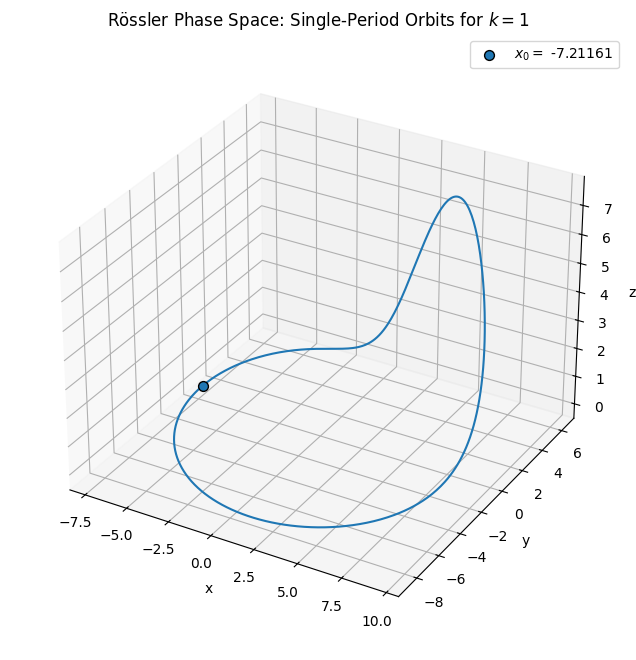

In [92]:
fig = plt.figure(figsize=(10, 8))

ax = fig.add_subplot(111, projection="3d")


ax.plot(phi_1[0], phi_1[1], phi_1[2],
        #  label="k = 1)",
        #  color="#2ca02c",
        )

ax.scatter(pts_1[:, 0], pts_1[:, 1], pts_1[:, 2],
            label = rf"$x_0 =$ {np.round(ics[0][0][0], 5)}",
            # color="#2ca02c",
            edgecolor="black",
            s=50)

ax.set_title(r"Rössler Phase Space: Single-Period Orbits for $k = 1$")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")
ax.legend()
ax.set_box_aspect(None, zoom=0.95) # so we can see the z-axis label
plt.show()

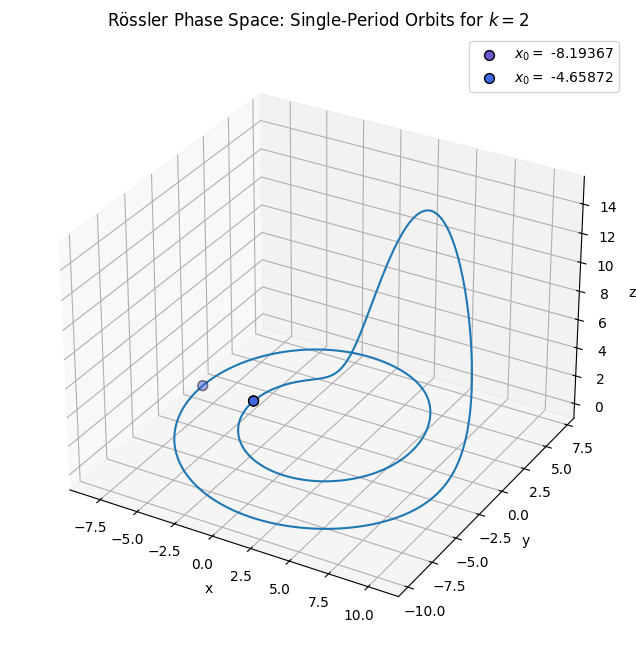

In [99]:
fig = plt.figure(figsize=(10, 8))

ax = fig.add_subplot(111, projection="3d")


ax.plot(phi_2_b[0], phi_2_b[1], phi_2_b[2],
        #  label="k = 2",
        )

ax.scatter(pts_2_a[:, 0], pts_2_a[:, 1], pts_2_a[:, 2],
            label = rf"$x_0 =$ {np.round(ics[1][0][0], 5)}",
            color="slateblue",
            edgecolor="black",
            s=50)

ax.scatter(pts_2_b[:, 0], pts_2_b[:, 1], pts_2_b[:, 2],
            label = rf"$x_0 =$ {np.round(ics[1][1][0], 5)}",
            color="royalblue",
            edgecolor="black",
            s=50)

ax.set_title(r"Rössler Phase Space: Single-Period Orbits for $k = 2$")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")

ax.legend()
ax.set_box_aspect(None, zoom=0.95) # so we can see the z-axis label
plt.show()

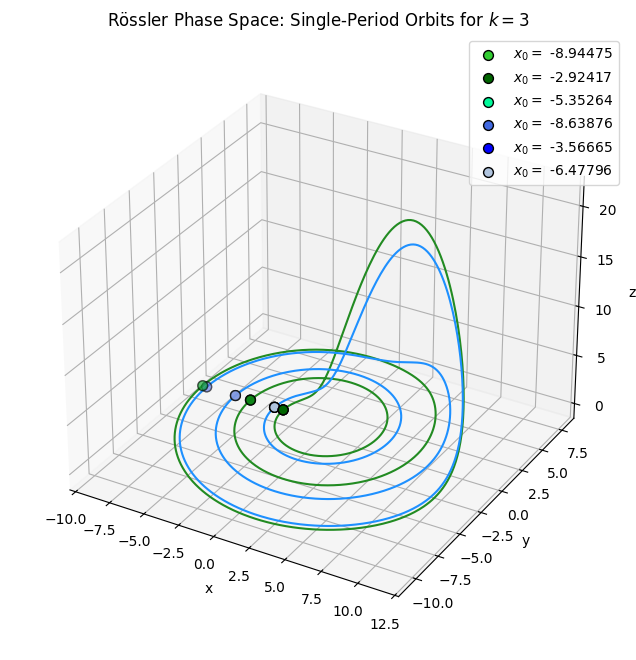

In [100]:
fig = plt.figure(figsize=(10, 8))

ax = fig.add_subplot(111, projection="3d")


ax.plot(phi_3_a[0], phi_3_a[1], phi_3_a[2],
        #  label="k = 2",
         color="forestgreen")

ax.plot(phi_3_d[0], phi_3_d[1], phi_3_d[2],
        #  label="k = 3",
         color="dodgerblue")

ax.scatter(pts_3_a[:, 0], pts_3_a[:, 1], pts_3_a[:, 2],
            label = rf"$x_0 =$ {np.round(ics[2][0][0], 5)}",
            color="limegreen",
            edgecolor="black",
            s=50)

ax.scatter(pts_3_b[:, 0], pts_3_b[:, 1], pts_3_b[:, 2],
            label = rf"$x_0 =$ {np.round(ics[2][1][0], 5)}",
            color="darkgreen",
            edgecolor="black",
            s=50)

ax.scatter(pts_3_c[:, 0], pts_3_c[:, 1], pts_3_c[:, 2],
            label = rf"$x_0 =$ {np.round(ics[2][2][0], 5)}",
            color="mediumspringgreen",
            edgecolor="black",
            s=50)

ax.scatter(pts_3_d[:, 0], pts_3_d[:, 1], pts_3_d[:, 2],
            label = rf"$x_0 =$ {np.round(ics[3][0][0], 5)}",
            color="royalblue",
            edgecolor="black",
            s=50)

ax.scatter(pts_3_e[:, 0], pts_3_e[:, 1], pts_3_e[:, 2],
            label = rf"$x_0 =$ {np.round(ics[3][1][0], 5)}",
            color="blue",
            edgecolor="black",
            s=50)

ax.scatter(pts_3_f[:, 0], pts_3_f[:, 1], pts_3_f[:, 2],
            label = rf"$x_0 =$ {np.round(ics[3][2][0], 5)}",
            color="lightsteelblue",
            edgecolor="black",
            s=50)

ax.set_title(r"Rössler Phase Space: Single-Period Orbits for $k = 3$")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_zlabel("z")

ax.legend()
ax.set_box_aspect(None, zoom=0.95) # so we can see the z-axis label
plt.show()